<a href="https://colab.research.google.com/github/dpadala541/MSAI-631-B01--AI-for-HCI/blob/main/Rec_System_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Setup & Dependencies

In [18]:
# Installing required packages
# !pip install pandas scikit-learn numpy ipywidgets

import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import csv
import random
import os
import warnings
warnings.filterwarnings('ignore')

print("All packages loaded successfully!")

All packages loaded successfully!


## 2. Dataset Generation

In [19]:
# ── Movie catalog: 100 movies with genres, year, and mood tags ──
MOVIES = [
    (1, "The Shawshank Redemption", 1994, "Drama", "inspiring"),
    (2, "The Godfather", 1972, "Crime|Drama", "intense"),
    (3, "The Dark Knight", 2008, "Action|Crime|Drama", "thrilling"),
    (4, "Pulp Fiction", 1994, "Crime|Drama", "edgy"),
    (5, "Forrest Gump", 1994, "Comedy|Drama|Romance", "heartwarming"),
    (6, "Inception", 2010, "Action|Sci-Fi|Thriller", "mind-bending"),
    (7, "The Matrix", 1999, "Action|Sci-Fi", "thrilling"),
    (8, "Goodfellas", 1990, "Biography|Crime|Drama", "intense"),
    (9, "The Silence of the Lambs", 1991, "Crime|Drama|Thriller", "suspenseful"),
    (10, "Se7en", 1995, "Crime|Drama|Mystery|Thriller", "dark"),
    (11, "It's a Wonderful Life", 1946, "Drama|Family|Fantasy", "heartwarming"),
    (12, "The Lion King", 1994, "Animation|Adventure|Drama", "heartwarming"),
    (13, "Spirited Away", 2001, "Animation|Adventure|Family", "whimsical"),
    (14, "Toy Story", 1995, "Animation|Adventure|Comedy", "fun"),
    (15, "Finding Nemo", 2003, "Animation|Adventure|Comedy", "fun"),
    (16, "The Avengers", 2012, "Action|Adventure|Sci-Fi", "thrilling"),
    (17, "Jurassic Park", 1993, "Action|Adventure|Sci-Fi", "thrilling"),
    (18, "Titanic", 1997, "Drama|Romance", "emotional"),
    (19, "Gladiator", 2000, "Action|Adventure|Drama", "inspiring"),
    (20, "Braveheart", 1995, "Biography|Drama|History", "inspiring"),
    (21, "The Departed", 2006, "Crime|Drama|Thriller", "intense"),
    (22, "Django Unchained", 2012, "Drama|Western", "edgy"),
    (23, "The Prestige", 2006, "Drama|Mystery|Sci-Fi|Thriller", "mind-bending"),
    (24, "Interstellar", 2014, "Adventure|Drama|Sci-Fi", "mind-bending"),
    (25, "Whiplash", 2014, "Drama|Music", "intense"),
    (26, "The Grand Budapest Hotel", 2014, "Adventure|Comedy|Crime", "whimsical"),
    (27, "Mad Max: Fury Road", 2015, "Action|Adventure|Sci-Fi", "thrilling"),
    (28, "Inside Out", 2015, "Animation|Adventure|Comedy", "emotional"),
    (29, "WALL-E", 2008, "Animation|Adventure|Family", "heartwarming"),
    (30, "Up", 2009, "Animation|Adventure|Comedy", "heartwarming"),
    (31, "Coco", 2017, "Animation|Adventure|Comedy", "emotional"),
    (32, "Ratatouille", 2007, "Animation|Comedy|Family", "fun"),
    (33, "The Incredibles", 2004, "Animation|Action|Adventure", "fun"),
    (34, "Frozen", 2013, "Animation|Adventure|Comedy", "fun"),
    (35, "Zootopia", 2016, "Animation|Adventure|Comedy", "fun"),
    (36, "Moana", 2016, "Animation|Adventure|Comedy", "inspiring"),
    (37, "Black Panther", 2018, "Action|Adventure|Sci-Fi", "inspiring"),
    (38, "Spider-Man: Into the Spider-Verse", 2018, "Animation|Action|Adventure", "thrilling"),
    (39, "Parasite", 2019, "Comedy|Drama|Thriller", "suspenseful"),
    (40, "Joker", 2019, "Crime|Drama|Thriller", "dark"),
    (41, "1917", 2019, "Drama|War", "intense"),
    (42, "Knives Out", 2019, "Comedy|Crime|Drama", "fun"),
    (43, "Jojo Rabbit", 2019, "Comedy|Drama|War", "whimsical"),
    (44, "Soul", 2020, "Animation|Adventure|Comedy", "inspiring"),
    (45, "Dune", 2021, "Action|Adventure|Drama", "mind-bending"),
    (46, "Everything Everywhere All at Once", 2022, "Action|Adventure|Sci-Fi", "mind-bending"),
    (47, "The Batman", 2022, "Action|Crime|Drama", "dark"),
    (48, "Top Gun: Maverick", 2022, "Action|Drama", "thrilling"),
    (49, "Oppenheimer", 2023, "Biography|Drama|History", "intense"),
    (50, "Barbie", 2023, "Adventure|Comedy|Fantasy", "fun"),
    (51, "Schindler's List", 1993, "Biography|Drama|History", "emotional"),
    (52, "Fight Club", 1999, "Drama", "edgy"),
    (53, "The Truman Show", 1998, "Comedy|Drama", "mind-bending"),
    (54, "Good Will Hunting", 1997, "Drama|Romance", "inspiring"),
    (55, "A Beautiful Mind", 2001, "Biography|Drama", "inspiring"),
    (56, "Catch Me If You Can", 2002, "Biography|Comedy|Crime", "fun"),
    (57, "The Pursuit of Happyness", 2006, "Biography|Drama", "inspiring"),
    (58, "Slumdog Millionaire", 2008, "Drama|Romance", "inspiring"),
    (59, "The Social Network", 2010, "Biography|Drama", "intense"),
    (60, "Gone Girl", 2014, "Drama|Mystery|Thriller", "dark"),
    (61, "Get Out", 2017, "Horror|Mystery|Thriller", "suspenseful"),
    (62, "A Quiet Place", 2018, "Drama|Horror|Sci-Fi", "suspenseful"),
    (63, "Hereditary", 2018, "Drama|Horror|Mystery", "dark"),
    (64, "Midsommar", 2019, "Drama|Horror|Mystery", "dark"),
    (65, "Us", 2019, "Horror|Mystery|Thriller", "suspenseful"),
    (66, "The Notebook", 2004, "Drama|Romance", "emotional"),
    (67, "La La Land", 2016, "Comedy|Drama|Music", "heartwarming"),
    (68, "Pride and Prejudice", 2005, "Drama|Romance", "heartwarming"),
    (69, "Eternal Sunshine of the Spotless Mind", 2004, "Drama|Romance|Sci-Fi", "emotional"),
    (70, "About Time", 2013, "Comedy|Drama|Fantasy", "heartwarming"),
    (71, "The Hangover", 2009, "Comedy", "fun"),
    (72, "Superbad", 2007, "Comedy", "fun"),
    (73, "Bridesmaids", 2011, "Comedy|Romance", "fun"),
    (74, "Step Brothers", 2008, "Comedy", "fun"),
    (75, "Anchorman", 2004, "Comedy", "fun"),
    (76, "Moneyball", 2011, "Biography|Drama|Sport", "inspiring"),
    (77, "The Big Short", 2015, "Biography|Comedy|Drama", "edgy"),
    (78, "Spotlight", 2015, "Biography|Crime|Drama", "intense"),
    (79, "12 Years a Slave", 2013, "Biography|Drama|History", "emotional"),
    (80, "Moonlight", 2016, "Drama", "emotional"),
    (81, "Lady Bird", 2017, "Comedy|Drama", "heartwarming"),
    (82, "Little Women", 2019, "Drama|Romance", "heartwarming"),
    (83, "Marriage Story", 2019, "Comedy|Drama|Romance", "emotional"),
    (84, "Uncut Gems", 2019, "Crime|Drama|Thriller", "intense"),
    (85, "The Lighthouse", 2019, "Drama|Fantasy|Horror", "dark"),
    (86, "Tenet", 2020, "Action|Sci-Fi|Thriller", "mind-bending"),
    (87, "Nomadland", 2020, "Drama", "emotional"),
    (88, "Minari", 2020, "Drama", "heartwarming"),
    (89, "Sound of Metal", 2019, "Drama|Music", "emotional"),
    (90, "Promising Young Woman", 2020, "Crime|Drama|Thriller", "edgy"),
    (91, "Bo Burnham: Inside", 2021, "Comedy|Music", "edgy"),
    (92, "The Power of the Dog", 2021, "Drama|Romance|Western", "suspenseful"),
    (93, "CODA", 2021, "Comedy|Drama|Music", "heartwarming"),
    (94, "Belfast", 2021, "Comedy|Drama", "heartwarming"),
    (95, "The Banshees of Inisherin", 2022, "Comedy|Drama", "dark"),
    (96, "Tar", 2022, "Drama|Music", "intense"),
    (97, "Glass Onion", 2022, "Comedy|Crime|Drama", "fun"),
    (98, "The Whale", 2022, "Drama", "emotional"),
    (99, "Past Lives", 2023, "Drama|Romance", "emotional"),
    (100, "Killers of the Flower Moon", 2023, "Crime|Drama|History", "intense"),
]

# Create movies DataFrame
movies_df = pd.DataFrame(MOVIES, columns=["movieId", "title", "year", "genres", "mood"])
print(f"Movie catalog: {len(movies_df)} movies")
print(f"Genres represented: {len(set(g for gs in movies_df['genres'] for g in gs.split('|')))} unique genres")
print(f"Mood tags: {sorted(movies_df['mood'].unique())}")
movies_df.head(10)

Movie catalog: 100 movies
Genres represented: 19 unique genres
Mood tags: ['dark', 'edgy', 'emotional', 'fun', 'heartwarming', 'inspiring', 'intense', 'mind-bending', 'suspenseful', 'thrilling', 'whimsical']


,movieId,title,year,genres,mood
0,1,The Shawshank Redemption,1994,Drama,inspiring
1,2,The Godfather,1972,Crime|Drama,intense
2,3,The Dark Knight,2008,Action|Crime|Drama,thrilling
3,4,Pulp Fiction,1994,Crime|Drama,edgy
4,5,Forrest Gump,1994,Comedy|Drama|Romance,heartwarming
5,6,Inception,2010,Action|Sci-Fi|Thriller,mind-bending
6,7,The Matrix,1999,Action|Sci-Fi,thrilling
7,8,Goodfellas,1990,Biography|Crime|Drama,intense
8,9,The Silence of the Lambs,1991,Crime|Drama|Thriller,suspenseful
9,10,Se7en,1995,Crime|Drama|Mystery|Thriller,dark


In [20]:
# ── Generate synthetic user ratings ──
random.seed(42)
ratings_data = []
n_users = 50

for uid in range(1, n_users + 1):
    n_ratings = random.randint(10, 40)
    rated_movies = random.sample(list(movies_df['movieId']), min(n_ratings, len(movies_df)))
    for mid in rated_movies:
        rating = round(random.uniform(1.0, 5.0) * 2) / 2  # half-star increments
        ratings_data.append({"userId": uid, "movieId": mid, "rating": rating})

ratings_df = pd.DataFrame(ratings_data)
print(f"Generated {len(ratings_df)} ratings from {n_users} users")
print(f"Average rating: {ratings_df['rating'].mean():.2f}")
ratings_df.head(10)

Generated 1320 ratings from 50 users
Average rating: 3.01


,userId,movieId,rating
0,1,15,4.0
1,1,4,2.5
2,1,95,1.5
3,1,36,5.0
4,1,32,2.5
5,1,29,1.5
6,1,18,1.5
7,1,14,4.5
8,1,87,3.5
9,1,70,4.0


## 3. Exploratory Data Analysis

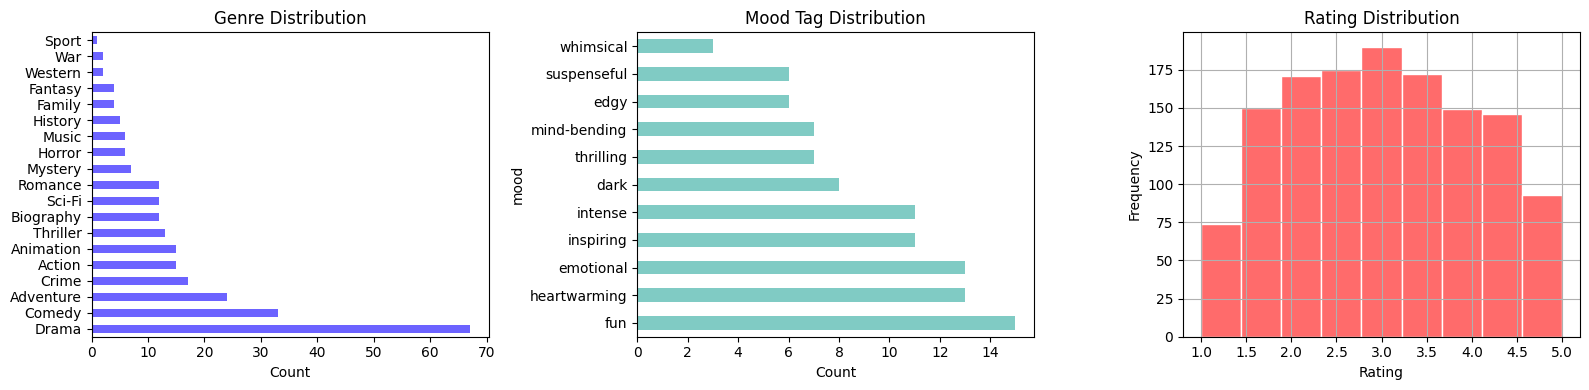

In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Genre distribution
all_genres = []
for gs in movies_df['genres']:
    all_genres.extend(gs.split('|'))
genre_counts = pd.Series(all_genres).value_counts()
genre_counts.plot(kind='barh', ax=axes[0], color='#6c63ff')
axes[0].set_title('Genre Distribution')
axes[0].set_xlabel('Count')

# Mood distribution
movies_df['mood'].value_counts().plot(kind='barh', ax=axes[1], color='#80cbc4')
axes[1].set_title('Mood Tag Distribution')
axes[1].set_xlabel('Count')

# Rating distribution
ratings_df['rating'].hist(bins=9, ax=axes[2], color='#ff6b6b', edgecolor='white')
axes[2].set_title('Rating Distribution')
axes[2].set_xlabel('Rating')
axes[2].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

In [5]:
# Decade distribution
movies_df['decade'] = (movies_df['year'] // 10) * 10
decade_counts = movies_df['decade'].value_counts().sort_index()
print("Movies per decade:")
for decade, count in decade_counts.items():
    print(f"  {decade}s: {count} movies")

Movies per decade:
  1940s: 1 movies
  1970s: 1 movies
  1990s: 16 movies
  2000s: 21 movies
  2010s: 40 movies
  2020s: 21 movies


## 4. Recommendation Engine

In [22]:
class MovieRecommender:
    """Content-based movie recommendation engine with hybrid scoring."""

    def __init__(self, movies: pd.DataFrame, ratings: pd.DataFrame):
        self.movies = movies.copy()
        self.ratings = ratings.copy()
        self._compute_popularity()
        self._build_content_model()

    # ── Popularity metrics ──
    def _compute_popularity(self):
        """Compute Bayesian weighted rating per movie (IMDB formula)."""
        rating_stats = (
            self.ratings.groupby("movieId")["rating"]
            .agg(["mean", "count"])
            .rename(columns={"mean": "avg_rating", "count": "vote_count"})
            .reset_index()
        )
        self.movies = self.movies.merge(rating_stats, on="movieId", how="left")
        self.movies["avg_rating"] = self.movies["avg_rating"].fillna(0)
        self.movies["vote_count"] = self.movies["vote_count"].fillna(0).astype(int)

        # WR = (v/(v+m))*R + (m/(v+m))*C
        C = self.movies["avg_rating"].mean()
        m = self.movies["vote_count"].quantile(0.25)
        self.movies["weighted_rating"] = self.movies.apply(
            lambda x: (x["vote_count"] / (x["vote_count"] + m)) * x["avg_rating"]
            + (m / (x["vote_count"] + m)) * C
            if x["vote_count"] > 0 else C,
            axis=1,
        )

    # ── TF-IDF content model ──
    def _build_content_model(self):
        """Build TF-IDF matrix from genre + mood + decade features."""
        self.movies["features"] = (
            self.movies["genres"].str.replace("|", " ", regex=False)
            + " " + self.movies["mood"]
            + " decade" + (self.movies["year"] // 10 * 10).astype(str) + "s"
        )
        self.tfidf = TfidfVectorizer(stop_words="english")
        self.tfidf_matrix = self.tfidf.fit_transform(self.movies["features"])
        self.cosine_sim = cosine_similarity(self.tfidf_matrix, self.tfidf_matrix)

    # ── Helpers ──
    def get_all_titles(self):
        return sorted(self.movies["title"].tolist())

    def get_all_genres(self):
        all_g = set()
        for gs in self.movies["genres"]:
            for g in gs.split("|"):
                all_g.add(g.strip())
        return sorted(all_g)

    def get_all_moods(self):
        return sorted(self.movies["mood"].unique().tolist())

    def get_movie_info(self, title):
        row = self.movies[self.movies["title"] == title]
        if row.empty:
            return None
        r = row.iloc[0]
        return {
            "title": r["title"], "year": int(r["year"]),
            "genres": r["genres"], "mood": r["mood"],
            "avg_rating": round(r["avg_rating"], 2),
            "vote_count": int(r["vote_count"]),
            "weighted_rating": round(r["weighted_rating"], 2),
        }

    # ── Explanation generator ──
    def _explain(self, seed_title, movie_row, content_score):
        """Generate a human-readable explanation for a recommendation."""
        seed = self.movies[self.movies["title"] == seed_title].iloc[0]
        seed_genres = set(seed["genres"].split("|"))
        movie_genres = set(movie_row["genres"].split("|"))
        shared = seed_genres & movie_genres

        parts = []
        if shared:
            parts.append(f"shares {', '.join(shared)} genre(s)")
        if seed["mood"] == movie_row["mood"]:
            parts.append(f"same '{movie_row['mood']}' mood")
        if abs(seed["year"] - movie_row["year"]) <= 5:
            parts.append("from a similar era")

        if parts:
            return f"Recommended because it {'; '.join(parts)} with {seed_title}."
        return f"Content similarity score: {content_score:.2f}."

    # ── Title-based recommendations ──
    def recommend_by_title(self, title, n=10, mood_filter=None,
                           genre_filter=None, min_year=None, max_year=None,
                           popularity_weight=0.3):
        """Hybrid recommendations: content similarity + popularity."""
        idx_matches = self.movies[self.movies["title"] == title].index
        if len(idx_matches) == 0:
            return pd.DataFrame()

        idx = idx_matches[0]
        sim_scores = list(enumerate(self.cosine_sim[idx]))

        max_wr = self.movies["weighted_rating"].max()
        min_wr = self.movies["weighted_rating"].min()
        wr_range = max_wr - min_wr if max_wr != min_wr else 1

        results = []
        for i, content_score in sim_scores:
            if i == idx:
                continue
            movie = self.movies.iloc[i]
            if mood_filter and movie["mood"] != mood_filter:
                continue
            if genre_filter and genre_filter not in movie["genres"]:
                continue
            if min_year and movie["year"] < min_year:
                continue
            if max_year and movie["year"] > max_year:
                continue

            pop_score = (movie["weighted_rating"] - min_wr) / wr_range
            hybrid_score = (1 - popularity_weight) * content_score + popularity_weight * pop_score
            explanation = self._explain(title, movie, content_score)

            results.append({
                "Title": movie["title"],
                "Year": int(movie["year"]),
                "Genres": movie["genres"].replace("|", ", "),
                "Mood": movie["mood"].capitalize(),
                "Avg Rating": round(movie["avg_rating"], 2),
                "Votes": int(movie["vote_count"]),
                "Content Score": round(content_score, 4),
                "Hybrid Score": round(hybrid_score, 4),
                "Explanation": explanation,
            })

        df = pd.DataFrame(results)
        if not df.empty:
            df = df.sort_values("Hybrid Score", ascending=False).head(n).reset_index(drop=True)
            df.index = df.index + 1  # 1-indexed
        return df

    # ── Mood-based recommendations ──
    def recommend_by_mood(self, mood, n=10):
        """Top-rated movies matching a mood tag."""
        filtered = self.movies[self.movies["mood"] == mood].copy()
        filtered = filtered.sort_values("weighted_rating", ascending=False).head(n)
        return filtered[["title", "year", "genres", "mood", "avg_rating",
                         "vote_count", "weighted_rating"]].reset_index(drop=True).rename(
            columns={"title": "Title", "year": "Year", "genres": "Genres",
                     "mood": "Mood", "avg_rating": "Avg Rating",
                     "vote_count": "Votes", "weighted_rating": "Weighted Rating"})

    # ── Genre-based recommendations ──
    def recommend_by_genre(self, genre, n=10):
        """Top-rated movies in a specific genre."""
        filtered = self.movies[self.movies["genres"].str.contains(genre, na=False)].copy()
        filtered = filtered.sort_values("weighted_rating", ascending=False).head(n)
        return filtered[["title", "year", "genres", "mood", "avg_rating",
                         "vote_count", "weighted_rating"]].reset_index(drop=True).rename(
            columns={"title": "Title", "year": "Year", "genres": "Genres",
                     "mood": "Mood", "avg_rating": "Avg Rating",
                     "vote_count": "Votes", "weighted_rating": "Weighted Rating"})


# Initialize the recommender
rec = MovieRecommender(movies_df, ratings_df)
print(f"Recommender initialized with {len(rec.movies)} movies")
print(f"TF-IDF matrix shape: {rec.tfidf_matrix.shape}")
print(f"Cosine similarity matrix shape: {rec.cosine_sim.shape}")
print(f"Feature vocabulary size: {len(rec.tfidf.vocabulary_)}")

Recommender initialized with 100 movies
TF-IDF matrix shape: (100, 38)
Cosine similarity matrix shape: (100, 100)
Feature vocabulary size: 38


## 5. TF-IDF Feature Analysis

In [23]:
# Show the TF-IDF feature names
feature_names = rec.tfidf.get_feature_names_out()
print(f"TF-IDF features ({len(feature_names)} total):")
print(feature_names)

TF-IDF features (38 total):
['action' 'adventure' 'animation' 'bending' 'biography' 'comedy' 'crime'
 'dark' 'decade1940s' 'decade1970s' 'decade1990s' 'decade2000s'
 'decade2010s' 'decade2020s' 'drama' 'edgy' 'emotional' 'family' 'fantasy'
 'fi' 'fun' 'heartwarming' 'history' 'horror' 'inspiring' 'intense' 'mind'
 'music' 'mystery' 'romance' 'sci' 'sport' 'suspenseful' 'thriller'
 'thrilling' 'war' 'western' 'whimsical']


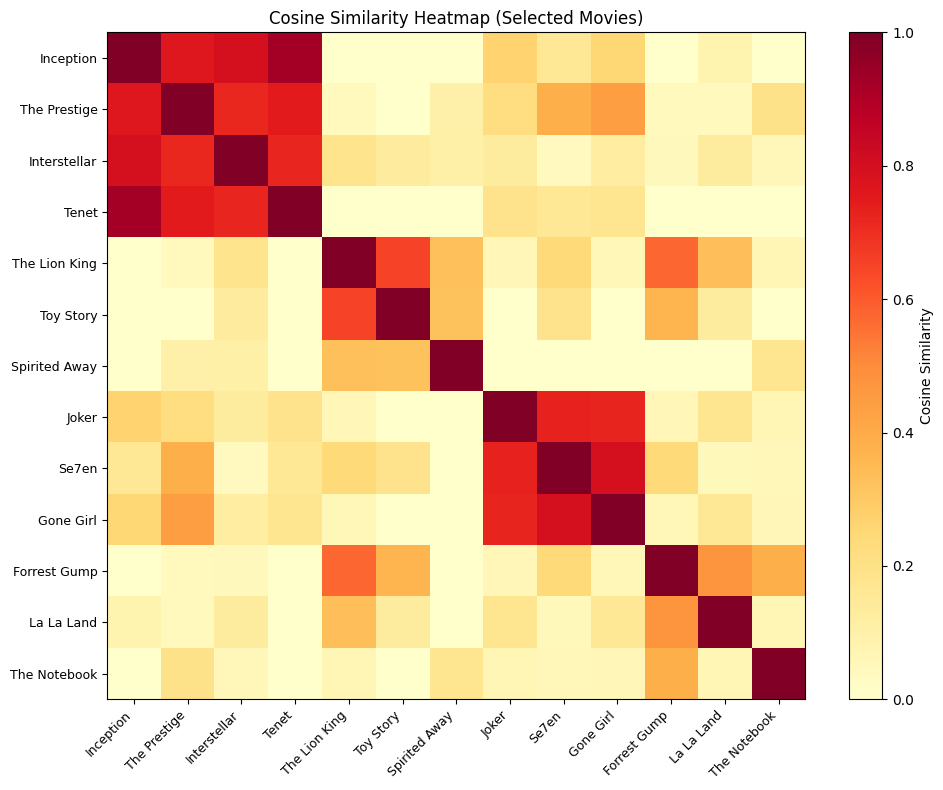

In [24]:
# Visualize cosine similarity heatmap for a subset of movies
import matplotlib.pyplot as plt
import numpy as np

subset_titles = ["Inception", "The Prestige", "Interstellar", "Tenet",
                 "The Lion King", "Toy Story", "Spirited Away",
                 "Joker", "Se7en", "Gone Girl",
                 "Forrest Gump", "La La Land", "The Notebook"]
subset_idx = [rec.movies[rec.movies["title"] == t].index[0] for t in subset_titles]
subset_sim = rec.cosine_sim[np.ix_(subset_idx, subset_idx)]

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(subset_sim, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(subset_titles)))
ax.set_yticks(range(len(subset_titles)))
ax.set_xticklabels(subset_titles, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(subset_titles, fontsize=9)
plt.colorbar(im, label="Cosine Similarity")
ax.set_title("Cosine Similarity Heatmap (Selected Movies)")
plt.tight_layout()
plt.show()

## 6. Demo: Title-Based Recommendations

In [25]:
# ── Recommend movies similar to "Inception" ──
print("=" * 70)
print("🎯 Movies similar to: Inception (2010)")
print("   Genres: Action, Sci-Fi, Thriller | Mood: Mind-bending")
print("=" * 70)

results = rec.recommend_by_title("Inception", n=8, popularity_weight=0.3)
display(results[["Title", "Year", "Genres", "Mood", "Hybrid Score", "Explanation"]])

🎯 Movies similar to: Inception (2010)
   Genres: Action, Sci-Fi, Thriller | Mood: Mind-bending


,Title,Year,Genres,Mood,Hybrid Score,Explanation
1,The Prestige,2006,"Drama, Mystery, Sci-Fi, Thriller",Mind-bending,0.7697,"Recommended because it shares Sci-Fi, Thriller..."
2,Tenet,2020,"Action, Sci-Fi, Thriller",Mind-bending,0.7369,"Recommended because it shares Sci-Fi, Thriller..."
3,Interstellar,2014,"Adventure, Drama, Sci-Fi",Mind-bending,0.6463,Recommended because it shares Sci-Fi genre(s);...
4,Dune,2021,"Action, Adventure, Drama",Mind-bending,0.5861,Recommended because it shares Action genre(s);...
5,Everything Everywhere All at Once,2022,"Action, Adventure, Sci-Fi",Mind-bending,0.5655,"Recommended because it shares Sci-Fi, Action g..."
6,Mad Max: Fury Road,2015,"Action, Adventure, Sci-Fi",Thrilling,0.5464,"Recommended because it shares Sci-Fi, Action g..."
7,The Truman Show,1998,"Comedy, Drama",Mind-bending,0.5313,Recommended because it same 'mind-bending' moo...
8,Black Panther,2018,"Action, Adventure, Sci-Fi",Inspiring,0.5197,"Recommended because it shares Sci-Fi, Action g..."


In [26]:
# ── Try another seed movie ──
print("=" * 70)
print("🎯 Movies similar to: Parasite (2019)")
print("   Genres: Comedy, Drama, Thriller | Mood: Suspenseful")
print("=" * 70)

results = rec.recommend_by_title("Parasite", n=8, popularity_weight=0.3)
display(results[["Title", "Year", "Genres", "Mood", "Hybrid Score", "Explanation"]])

🎯 Movies similar to: Parasite (2019)
   Genres: Comedy, Drama, Thriller | Mood: Suspenseful


,Title,Year,Genres,Mood,Hybrid Score,Explanation
1,Get Out,2017,"Horror, Mystery, Thriller",Suspenseful,0.6185,Recommended because it shares Thriller genre(s...
2,The Silence of the Lambs,1991,"Crime, Drama, Thriller",Suspenseful,0.6165,"Recommended because it shares Drama, Thriller ..."
3,Uncut Gems,2019,"Crime, Drama, Thriller",Intense,0.5392,"Recommended because it shares Drama, Thriller ..."
4,Us,2019,"Horror, Mystery, Thriller",Suspenseful,0.5194,Recommended because it shares Thriller genre(s...
5,Joker,2019,"Crime, Drama, Thriller",Dark,0.4982,"Recommended because it shares Drama, Thriller ..."
6,A Quiet Place,2018,"Drama, Horror, Sci-Fi",Suspenseful,0.4754,Recommended because it shares Drama genre(s); ...
7,Promising Young Woman,2020,"Crime, Drama, Thriller",Edgy,0.4500,"Recommended because it shares Drama, Thriller ..."
8,Gone Girl,2014,"Drama, Mystery, Thriller",Dark,0.4470,"Recommended because it shares Drama, Thriller ..."


In [27]:
# ── With mood filter: only 'dark' movies similar to Se7en ──
print("=" * 70)
print("🎯 Dark movies similar to: Se7en (1995)")
print("   Filter: mood = 'dark'")
print("=" * 70)

results = rec.recommend_by_title("Se7en", n=8, mood_filter="dark")
display(results[["Title", "Year", "Genres", "Mood", "Hybrid Score", "Explanation"]])

🎯 Dark movies similar to: Se7en (1995)
   Filter: mood = 'dark'


,Title,Year,Genres,Mood,Hybrid Score,Explanation
1,Gone Girl,2014,"Drama, Mystery, Thriller",Dark,0.7175,"Recommended because it shares Drama, Mystery, ..."
2,Joker,2019,"Crime, Drama, Thriller",Dark,0.7018,"Recommended because it shares Crime, Drama, Th..."
3,Midsommar,2019,"Drama, Horror, Mystery",Dark,0.5619,"Recommended because it shares Drama, Mystery g..."
4,The Batman,2022,"Action, Crime, Drama",Dark,0.5131,"Recommended because it shares Crime, Drama gen..."
5,Hereditary,2018,"Drama, Horror, Mystery",Dark,0.4845,"Recommended because it shares Drama, Mystery g..."
6,The Lighthouse,2019,"Drama, Fantasy, Horror",Dark,0.3717,Recommended because it shares Drama genre(s); ...
7,The Banshees of Inisherin,2022,"Comedy, Drama",Dark,0.3441,Recommended because it shares Drama genre(s); ...


## 7. Demo: Mood-Based Recommendations


In [28]:
# ── Heartwarming movies ──
print("😊 Mood: Heartwarming")
print("   'Feel-good stories that warm the soul'")
print()
display(rec.recommend_by_mood("heartwarming", n=8))

😊 Mood: Heartwarming
   'Feel-good stories that warm the soul'



,Title,Year,Genres,Mood,Avg Rating,Votes,Weighted Rating
0,Up,2009,Animation|Adventure|Comedy,heartwarming,3.571429,14,3.320320
1,Belfast,2021,Comedy|Drama,heartwarming,3.411765,17,3.250285
2,WALL-E,2008,Animation|Adventure|Family,heartwarming,3.208333,12,3.109043
3,La La Land,2016,Comedy|Drama|Music,heartwarming,3.250000,8,3.105684
4,Forrest Gump,1994,Comedy|Drama|Romance,heartwarming,3.222222,9,3.100399
5,CODA,2021,Comedy|Drama|Music,heartwarming,3.147059,17,3.089571
6,It's a Wonderful Life,1946,Drama|Family|Fantasy,heartwarming,3.093750,16,3.055851
7,Little Women,2019,Drama|Romance,heartwarming,2.944444,9,2.975399


In [29]:
# ── Mind-bending movies ──
print("🌀 Mood: Mind-bending")
print("   'Movies that challenge your perception'")
print()
display(rec.recommend_by_mood("mind-bending", n=8))

🌀 Mood: Mind-bending
   'Movies that challenge your perception'



,Title,Year,Genres,Mood,Avg Rating,Votes,Weighted Rating
0,The Prestige,2006,Drama|Mystery|Sci-Fi|Thriller,mind-bending,3.541667,12,3.282956
1,The Truman Show,1998,Comedy|Drama,mind-bending,3.230769,13,3.125333
2,Dune,2021,Action|Adventure|Drama,mind-bending,3.166667,9,3.075399
3,Inception,2010,Action|Sci-Fi|Thriller,mind-bending,3.050000,10,3.024190
4,Tenet,2020,Action|Sci-Fi|Thriller,mind-bending,2.763158,19,2.850266
5,Interstellar,2014,Adventure|Drama|Sci-Fi,mind-bending,2.708333,12,2.848173
6,Everything Everywhere All at Once,2022,Action|Adventure|Sci-Fi,mind-bending,2.000000,8,2.579368


## 8. Demo: Genre Explorer

In [30]:
# ── Top Animation movies ──
print("🎭 Genre: Animation")
print()
display(rec.recommend_by_genre("Animation", n=8))

🎭 Genre: Animation



,Title,Year,Genres,Mood,Avg Rating,Votes,Weighted Rating
0,Up,2009,Animation|Adventure|Comedy,heartwarming,3.571429,14,3.320320
1,Frozen,2013,Animation|Adventure|Comedy,fun,3.600000,10,3.286095
2,Inside Out,2015,Animation|Adventure|Comedy,emotional,3.409091,11,3.204909
3,Soul,2020,Animation|Adventure|Comedy,inspiring,3.214286,14,3.120320
4,WALL-E,2008,Animation|Adventure|Family,heartwarming,3.208333,12,3.109043
5,Moana,2016,Animation|Adventure|Comedy,inspiring,3.136364,11,3.068545
6,The Incredibles,2004,Animation|Action|Adventure,fun,3.038462,13,3.021166
7,Zootopia,2016,Animation|Adventure|Comedy,fun,2.964286,14,2.980320


In [31]:
# ── Top Thriller movies ──
print("🎭 Genre: Thriller")
print()
display(rec.recommend_by_genre("Thriller", n=8))

🎭 Genre: Thriller



,Title,Year,Genres,Mood,Avg Rating,Votes,Weighted Rating
0,The Prestige,2006,Drama|Mystery|Sci-Fi|Thriller,mind-bending,3.541667,12,3.282956
1,Promising Young Woman,2020,Crime|Drama|Thriller,edgy,3.541667,12,3.282956
2,Uncut Gems,2019,Crime|Drama|Thriller,intense,3.394737,19,3.250266
3,The Departed,2006,Crime|Drama|Thriller,intense,3.375000,12,3.195999
4,Joker,2019,Crime|Drama|Thriller,dark,3.266667,15,3.154153
5,Get Out,2017,Horror|Mystery|Thriller,suspenseful,3.192308,13,3.104499
6,Gone Girl,2014,Drama|Mystery|Thriller,dark,3.115385,13,3.062833
7,Inception,2010,Action|Sci-Fi|Thriller,mind-bending,3.050000,10,3.024190


## 9. Hybrid Scoring Analysis

In [33]:
# Comparing recommendations at different popularity weights
seed = "The Dark Knight"
print(f"Seed movie: {seed}\n")

for w in [0.0, 0.3, 0.7, 1.0]:
    results = rec.recommend_by_title(seed, n=5, popularity_weight=w)
    print(f"--- Popularity weight = {w} ---")
    if not results.empty:
        for _, r in results.iterrows():
            print(f"  {r['Title']} ({r['Year']}) | Score: {r['Hybrid Score']:.3f}")
    print()

Seed movie: The Dark Knight

--- Popularity weight = 0.0 ---
  Top Gun: Maverick (2022) | Score: 0.695
  Spider-Man: Into the Spider-Verse (2018) | Score: 0.554
  The Matrix (1999) | Score: 0.498
  The Avengers (2012) | Score: 0.490
  Mad Max: Fury Road (2015) | Score: 0.490

--- Popularity weight = 0.3 ---
  Top Gun: Maverick (2022) | Score: 0.550
  The Departed (2006) | Score: 0.517
  Mad Max: Fury Road (2015) | Score: 0.509
  Gladiator (2000) | Score: 0.508
  Spider-Man: Into the Spider-Verse (2018) | Score: 0.506

--- Popularity weight = 0.7 ---
  A Beautiful Mind (2001) | Score: 0.779
  Titanic (1997) | Score: 0.647
  Up (2009) | Score: 0.630
  Promising Young Woman (2020) | Score: 0.622
  Catch Me If You Can (2002) | Score: 0.618

--- Popularity weight = 1.0 ---
  A Beautiful Mind (2001) | Score: 1.000
  Titanic (1997) | Score: 0.898
  Up (2009) | Score: 0.822
  Frozen (2013) | Score: 0.784
  Whiplash (2014) | Score: 0.784



## 10. Interactive Interface (Widgets)

In [34]:
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output

    # ── Mode selector ──
    mode_dropdown = widgets.Dropdown(
        options=["Title-Based", "Mood-Based", "Genre Explorer"],
        value="Title-Based",
        description="Mode:",
        style={"description_width": "60px"},
    )

    # ── Title-based controls ──
    title_dropdown = widgets.Dropdown(
        options=rec.get_all_titles(),
        value="Inception",
        description="Movie:",
        style={"description_width": "60px"},
        layout=widgets.Layout(width="400px"),
    )

    mood_filter_dropdown = widgets.Dropdown(
        options=["Any"] + rec.get_all_moods(),
        value="Any",
        description="Mood filter:",
        style={"description_width": "80px"},
    )

    pop_slider = widgets.FloatSlider(
        value=0.3, min=0, max=1, step=0.1,
        description="Pop. weight:",
        style={"description_width": "80px"},
    )

    n_slider = widgets.IntSlider(
        value=8, min=3, max=15, step=1,
        description="Results:",
        style={"description_width": "80px"},
    )

    # ── Mood-based controls ──
    mood_dropdown = widgets.Dropdown(
        options=rec.get_all_moods(),
        value="heartwarming",
        description="Mood:",
        style={"description_width": "60px"},
    )

    # ── Genre controls ──
    genre_dropdown = widgets.Dropdown(
        options=rec.get_all_genres(),
        value="Drama",
        description="Genre:",
        style={"description_width": "60px"},
    )

    # ── Button and output ──
    button = widgets.Button(
        description="🔍 Get Recommendations",
        button_style="primary",
        layout=widgets.Layout(width="200px"),
    )
    output = widgets.Output()

    # ── Containers ──
    title_controls = widgets.VBox([title_dropdown, mood_filter_dropdown, pop_slider, n_slider])
    mood_controls = widgets.VBox([mood_dropdown, n_slider])
    genre_controls = widgets.VBox([genre_dropdown, n_slider])

    control_stack = widgets.VBox([title_controls])

    def on_mode_change(change):
        if change["new"] == "Title-Based":
            control_stack.children = [title_controls]
        elif change["new"] == "Mood-Based":
            control_stack.children = [mood_controls]
        else:
            control_stack.children = [genre_controls]

    mode_dropdown.observe(on_mode_change, names="value")

    def on_button_click(b):
        with output:
            clear_output()
            mode = mode_dropdown.value
            n = n_slider.value

            if mode == "Title-Based":
                mf = None if mood_filter_dropdown.value == "Any" else mood_filter_dropdown.value
                results = rec.recommend_by_title(
                    title_dropdown.value, n=n,
                    mood_filter=mf,
                    popularity_weight=pop_slider.value
                )
                info = rec.get_movie_info(title_dropdown.value)
                print(f"🎯 Similar to: {info['title']} ({info['year']})")
                print(f"   Genres: {info['genres']} | Mood: {info['mood']}")
                print()
                if not results.empty:
                    display(results[["Title", "Year", "Genres", "Mood",
                                    "Hybrid Score", "Explanation"]])
                else:
                    print("No matches found — try different filters.")

            elif mode == "Mood-Based":
                results = rec.recommend_by_mood(mood_dropdown.value, n=n)
                print(f"😊 Mood: {mood_dropdown.value.capitalize()}")
                print()
                display(results)

            else:
                results = rec.recommend_by_genre(genre_dropdown.value, n=n)
                print(f"🎭 Genre: {genre_dropdown.value}")
                print()
                display(results)

    button.on_click(on_button_click)

    print("🎬 AI Movie Recommender — Interactive Mode")
    print("Select a mode, adjust controls, and click the button.\n")
    display(widgets.VBox([mode_dropdown, control_stack, button, output]))

except ImportError:
    print("ipywidgets not available. Run: !pip install ipywidgets")
    print("The demos above still work without widgets.")

🎬 AI Movie Recommender — Interactive Mode
Select a mode, adjust controls, and click the button.

